In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import numpy as np
from mytools.halo_new import get_coord, get_mask_sector, get_mask_square 
from mytools.plot import plot_heatmap, plot_stack_fit_res, plot_axlines
from crafts_stack.halo_fitting import build_model, halofit
from astropy.stats import sigma_clip
from mytools.data import read_h5, vitems

<Axes: title={'center': 'Test'}, xlabel='X', ylabel='Y'>

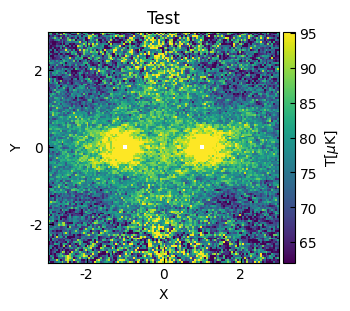

In [3]:
# data = np.load('../data/tng_pairstack_result_cube.npz', 'r')['data']
# data = np.load('../data/tng_pairstack_result_hpmap.npz', 'r')['data']
data = np.load('../data/crafts_pairstack_result_airpls.npz', 'r')['data']

data = sigma_clip(data, sigma=10, masked=True)
plot_heatmap(data, title='Test')

In [79]:
coord = get_coord()

name = 'gaussian'
# bg_name = 'poly'
bg_name = 'const'

tolenrance = 0.1

bounds = {
    'amplitude_0': (0, 200),
    'amplitude_1': (0, 200),
    # 'x_mean_0': (-1 - tolenrance, -1 + tolenrance),
    # 'x_mean_1': (1 - tolenrance, 1 + tolenrance),
    # 'y_mean_0': (0 - tolenrance, 0 + tolenrance),
    # 'y_mean_1': (0 - tolenrance, 0 + tolenrance),
    # 'ellipticity_0': (0, 0.5),
    # 'ellipticity_1': (0, 0.5),
    # 'theta_0': (0, 10),
    # 'theta_1': (0, 10),
    # 'r_s_0': (0.1, 10),
    # 'r_s_1': (0.1, 10),
}

constraints = {
    # "fixed": ['ellipticity_0', 'ellipticity_1'],
    "fixed": ['x_mean_0', 'y_mean_0', 'x_mean_1', 'y_mean_1'], # fix the center of the two NFW profiles
    "tied": [
        ("amplitude_1", "amplitude_0"),  # amplitude_1 = amplitude_0
        # ("ellipticity_1", "ellipticity_0"),
        ("x_stddev_0", "y_stddev_0"),
        ("x_stddev_1", "y_stddev_1"),
        # ("r_s_1", "r_s_2"),
        # ('c0_0_2', 'c0_0_3'),  
        # ('c1_0_2', 'c1_0_3'),  
        # ('c2_0_2', 'c2_0_3'), 
        # ('c0_1_2', 'c0_1_3'),
        # ('c0_2_2', 'c0_2_3'),
        # ('c1_1_2', 'c1_1_3'),
    ]
}

# init_bg = {
#     "degree": 1
# }

model = build_model(name, bg_name,bounds=bounds, constraints=constraints)
print(model)

Model: CompoundModel
Inputs: ('x', 'y')
Outputs: ('z',)
Model set size: 1
Expression: [0] + [1] + [2]
Components: 
    [0]: <Gaussian2D(amplitude=50., x_mean=-1., y_mean=0., x_stddev=0.5, y_stddev=0.5, theta=0.)>

    [1]: <Gaussian2D(amplitude=50., x_mean=1., y_mean=0., x_stddev=0.5, y_stddev=0.5, theta=0.)>

    [2]: <Const2D(amplitude=0.)>
Parameters:
    amplitude_0 x_mean_0 y_mean_0 x_stddev_0 ... y_stddev_1 theta_1 amplitude_2
    ----------- -------- -------- ---------- ... ---------- ------- -----------
           50.0     -1.0      0.0        0.5 ...        0.5     0.0         0.0


In [80]:
# pixcount weight
weight_path= '../data/pixcount_xsize3000_nfs10.h5'
vitems(weight_path)

Item: crafts_122k
Type: Group
Attributes (0):
 None
Item: crafts_122k/npair
Type: Dataset
Shape: ()
Dtype: int64
Attributes (0):
 None
Item: crafts_122k/pixcount
Type: Dataset
Shape: (21, 120, 120)
Dtype: int64
Attributes (0):
 None
Item: crafts_122k/weight
Type: Dataset
Shape: (120, 120)
Dtype: float64
Attributes (0):
 None
Item: tng_120k
Type: Group
Attributes (0):
 None
Item: tng_120k/npair
Type: Dataset
Shape: ()
Dtype: int64
Attributes (0):
 None
Item: tng_120k/pixcount
Type: Dataset
Shape: (21, 120, 120)
Dtype: int64
Attributes (0):
 None
Item: tng_120k/weight
Type: Dataset
Shape: (120, 120)
Dtype: float64
Attributes (0):
 None


<Axes: title={'center': 'Weight'}, xlabel='X', ylabel='Y'>

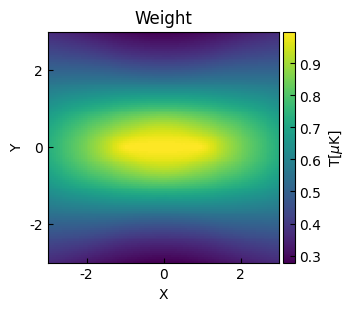

In [81]:
# weights = read_h5(weight_path, 'tng_120k/weight')
weights = read_h5(weight_path, 'crafts_122k/weight')
plot_heatmap(weights, title='Weight', q=0.1)

# without mask

In [83]:
data_list, fit_info = halofit(coord, data, model=model, print_model=True, weights=weights)


Fitted double NFW model:
Model: CompoundModel
Inputs: ('x', 'y')
Outputs: ('z',)
Model set size: 1
Expression: [0] + [1] + [2]
Components: 
    [0]: <Gaussian2D(amplitude=29.95636896, x_mean=-1., y_mean=0., x_stddev=0.49742779, y_stddev=0.49742779, theta=-278.90114776)>

    [1]: <Gaussian2D(amplitude=29.95636896, x_mean=1., y_mean=0., x_stddev=0.49070584, y_stddev=0.49070584, theta=232.48018282)>

    [2]: <Const2D(amplitude=76.55414419)>
Parameters:
       amplitude_0     x_mean_0 y_mean_0 ...      theta_1          amplitude_2   
    ------------------ -------- -------- ... ------------------ -----------------
    29.956368958791636     -1.0      0.0 ... 232.48018281657366 76.55414419092496

Goodness of fit:
Chi-squared: 1060222.524
RMS residual: 8.583


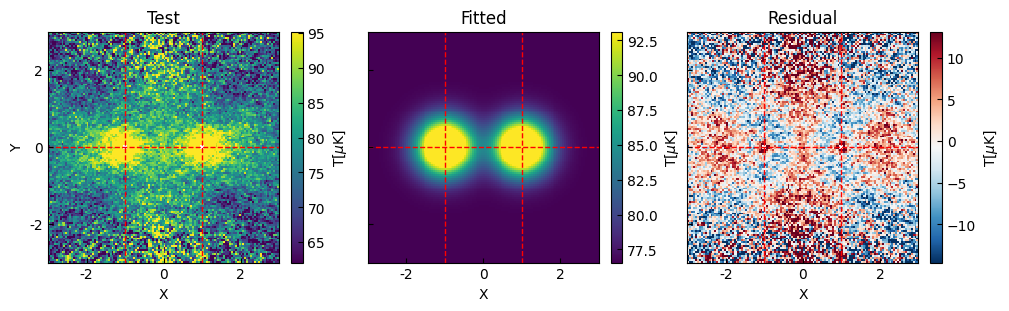

In [84]:
title = ['Test', 'Fitted', 'Residual']
axes =  plot_stack_fit_res(data_list, title=title)
plot_axlines(ax=axes, vl=[40, 80], hl=[60])

# with mask sector 

<Axes: title={'center': 'Mask'}, xlabel='X', ylabel='Y'>

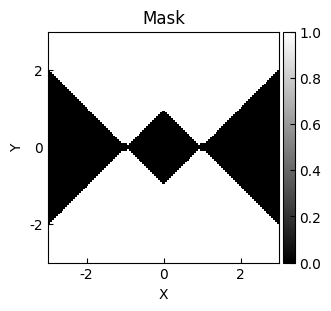

In [85]:
# mask = get_mask_sector(coord=coord)
mask = get_mask_sector(rlim=[0.1,5], coord=coord)
# mask = get_mask_sector(thetalim=[-np.pi/3, np.pi/3], coord=coord)
plot_heatmap(mask, title='Mask', cmap='gray', cbar_label='')

In [86]:
data_list_sector, fit_info = halofit(coord, data, model=model, mask=mask, print_model=True, weights=weights[mask])


Fitted double NFW model:
Model: CompoundModel
Inputs: ('x', 'y')
Outputs: ('z',)
Model set size: 1
Expression: [0] + [1] + [2]
Components: 
    [0]: <Gaussian2D(amplitude=29.95186676, x_mean=-1., y_mean=0., x_stddev=0.45709594, y_stddev=0.45709594, theta=384337.19735875)>

    [1]: <Gaussian2D(amplitude=29.95186676, x_mean=1., y_mean=0., x_stddev=0.44298904, y_stddev=0.44298904, theta=15443.20451154)>

    [2]: <Const2D(amplitude=76.06580592)>
Parameters:
       amplitude_0     x_mean_0 y_mean_0 ...      theta_1          amplitude_2   
    ------------------ -------- -------- ... ------------------ -----------------
    29.951866760292376     -1.0      0.0 ... 15443.204511536122 76.06580592165902

Goodness of fit:
Chi-squared: 1070918.238
RMS residual: 8.626


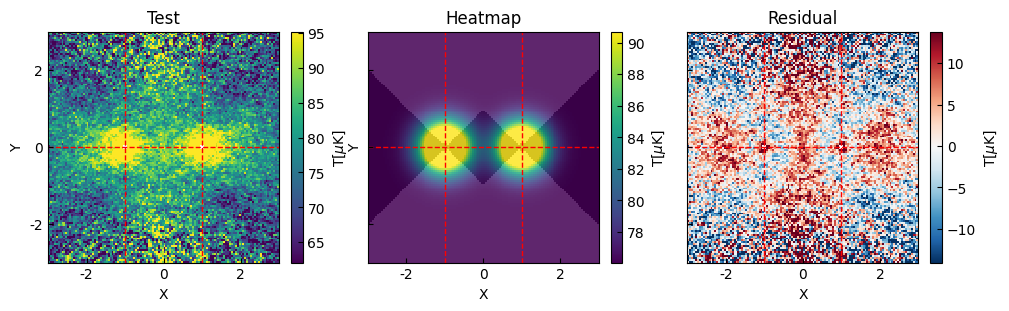

In [87]:
title = ['Test', 'Fitted', 'Residual']
axes =  plot_stack_fit_res(data_list_sector, title=title, fit_mask=mask)
plot_axlines(ax=axes, vl=[40, 80], hl=[60])

# with mask square

<Axes: title={'center': 'Mask'}, xlabel='X', ylabel='Y'>

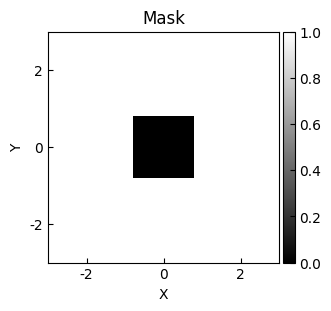

In [101]:
# mask = ~get_mask_square(coord=coord)
mask = ~get_mask_square(coord=coord, xlim=[-0.8, 0.8], ylim=[-0.8, 0.8])
plot_heatmap(mask, title='Mask', cmap='gray', cbar_label='')

In [102]:
data_list_square, fit_info = halofit(coord, data, model=model, mask=mask, print_model=True, weights=weights[mask])


Fitted double NFW model:
Model: CompoundModel
Inputs: ('x', 'y')
Outputs: ('z',)
Model set size: 1
Expression: [0] + [1] + [2]
Components: 
    [0]: <Gaussian2D(amplitude=33.45709417, x_mean=-1., y_mean=0., x_stddev=0.45973746, y_stddev=0.45973746, theta=-2264.63728923)>

    [1]: <Gaussian2D(amplitude=33.45709417, x_mean=1., y_mean=0., x_stddev=0.45030481, y_stddev=0.45030481, theta=2195.43431081)>

    [2]: <Const2D(amplitude=76.74482735)>
Parameters:
       amplitude_0    x_mean_0 y_mean_0 ...      theta_1         amplitude_2   
    ----------------- -------- -------- ... ----------------- -----------------
    33.45709416847973     -1.0      0.0 ... 2195.434310811148 76.74482734583952

Goodness of fit:
Chi-squared: 1067102.989
RMS residual: 8.611


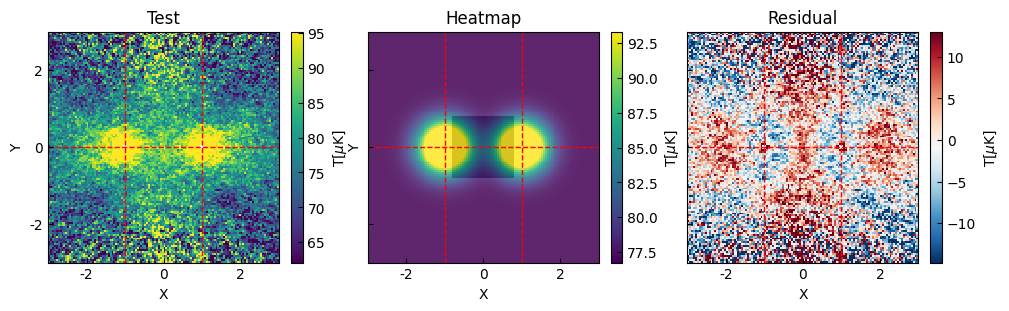

In [103]:
title = ['Test', 'Fitted', 'Residual']
axes =  plot_stack_fit_res(data_list_square, title=title, fit_mask=mask)
plot_axlines(ax=axes, vl=[40, 80], hl=[60])

# compare

In [104]:
from mytools.plot import plot_hist

(-100.0, 100.0)

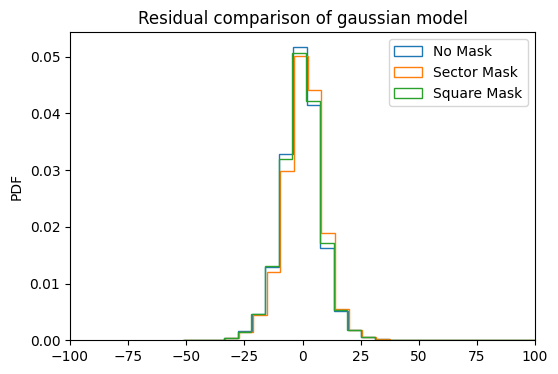

In [105]:
res_list = [data_list[-1].flatten(), data_list_sector[-1].flatten(), data_list_square[-1].flatten()]
labels = ['No Mask', 'Sector Mask', 'Square Mask']
title = 'Residual comparison of %s model' %(name)
ax = plot_hist(res_list, label=labels, bins=100, title=title)
ax.set_xlim(-100, 100)

# profiles

In [106]:
from mytools.plot import plot_line_diff, make_figure, plt, set_ticks

In [107]:
stack_fit_res = data_list
# stack_fit_res = data_list_sector
# stack_fit_res = data_list_square

In [108]:
get_yprofile = lambda dlist, ind: [x[ind,:] for x in dlist]
get_xprofile = lambda dlist, ind: [x[:,ind] for x in dlist]

lines_list = [
    get_yprofile(stack_fit_res[:2], 60),
    get_xprofile(stack_fit_res[:2], 40),
    get_xprofile(stack_fit_res[:2], 80),
]
title_list = ['Y=0', 'X=-1', 'X=1']

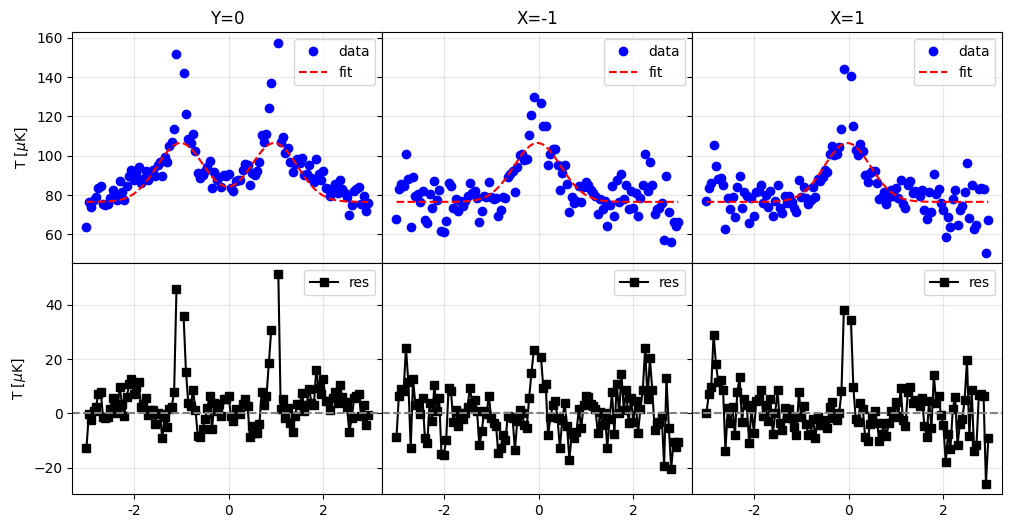

In [109]:
fig, axes = make_figure(2,3, figsize=(12,6), wspace=0., hspace=0.,aspect=None,sharex=True, sharey='row')

for i, lines in enumerate(lines_list):
    _axes = [axes[0,i], axes[1,i]]

    plot_line_diff(*lines, title=title_list[i], axes=_axes, labels=['data', 'fit', 'res'])

axes[0,0].set_ylabel(r'T [$\mu$K]')
axes[1,0].set_ylabel(r'T [$\mu$K]')
set_ticks(axes[1,0], share=False)

# estimate signal level

In [110]:
from mytools.estimate import get_signal_level
from mytools.plot import plot_profile_2c, plot_hist, make_figure

Parameter names:
('amplitude_0', 'mean_0', 'stddev_0', 'amplitude_1')
Gauss fit parameters: [np.float64(-5.583517762917735), np.float64(0.0), np.float64(0.7), np.float64(5.808572044601051)]
Gauss fit covariance: 
[[ 0.15294743 -0.00768506 -0.10168803]
 [-0.00768506  0.00456208  0.01730599]
 [-0.10168803  0.01730599  0.12129279]]
0 points clipped during sigma clipping.
width: 0.7
width_pix: 14


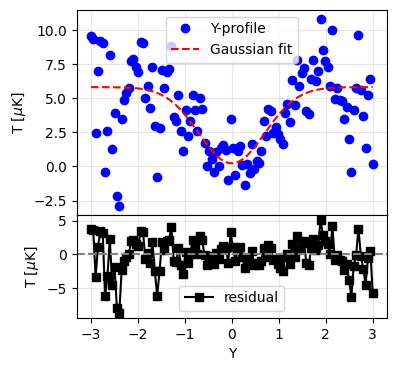

In [111]:
res = stack_fit_res[-1]
# bounds = (
#     [0, 0.1, -np.inf],
#     [np.inf, 0.7, np.inf],
# )
bounds = {
    "amplitude_0": (-np.inf, np.inf),  # amp > 0
    "stddev_0": (0, 0.7),  # sigma
}
lx, ly, clrb, params, cov = get_signal_level(res, weights, bounds=bounds, sigma_clip_sigma=None, show_fit=True);
# lx, ly, clrb, params, cov = get_signal_level(res, bounds=bounds, sigma_clip_sigma=5, weights=weight[:,50:70].mean(axis=1), show_fit=False);
# lx, ly, clrb, params, cov = get_signal_level(res);

array([<Axes: title={'center': 'Transverse-section profile'}, xlabel='Y', ylabel='$T$[$\\mu$K]'>,
       <Axes: title={'center': 'Lengthwise-section profile'}, xlabel='X'>],
      dtype=object)

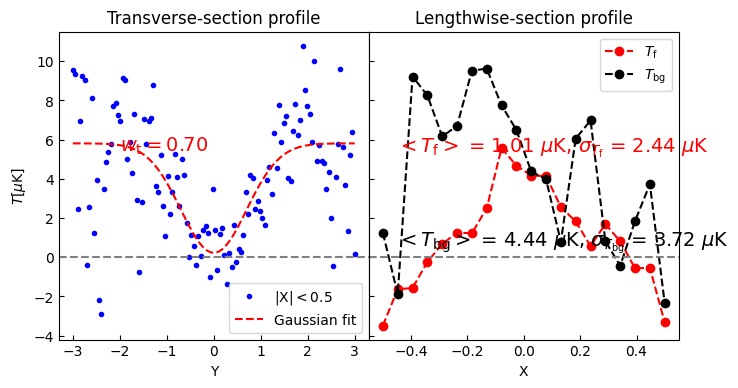

In [112]:
text_pos = [
    [-0.45, 0.5 * np.max(ly[0])], 
    [-0.45, -0.2* np.min(ly[0])], 
    [-2, 0.5 * np.max(ly[0])],
]
fig, axes = make_figure(1, 2, figsize=(8,4),wspace=0.,aspect=None,sharex=False)
plot_profile_2c(lx, ly, axes=axes, width=params[2], text_pos=text_pos)

<Axes: title={'center': 'Signal level'}, ylabel='PDF'>

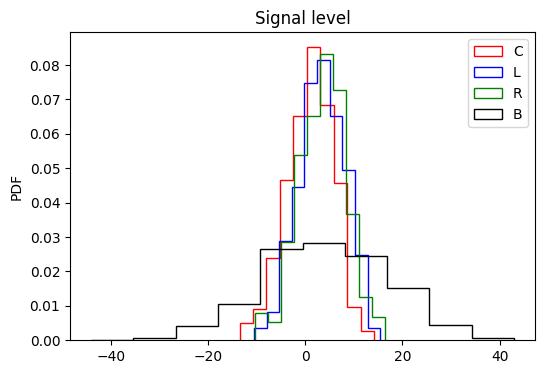

In [100]:
plot_hist(clrb, label=['C','L','R','B'], color=['r', 'b','g','k'], title='Signal level')